# Week 2 — Exploratory Data Analysis: NextGenLearners Applicant Insights

**Author:** Nabia

**Goal:** explore the cleaned applicant data from Week 1 and find patterns a program manager can act on.

Every section follows the same story: **question → code → chart → takeaway**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

df = pd.read_csv('applicants_cleaned.csv', parse_dates=['Application Date'])

## Step 1 — Quick sanity check

`parse_dates` was used so that `Application Date` comes back as a real date column (a CSV only stores plain text).

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    75 non-null     str           
 1   Email             75 non-null     str           
 2   Phone             75 non-null     int64         
 3   Domain Applied    75 non-null     str           
 4   University        75 non-null     str           
 5   Application Date  75 non-null     datetime64[us]
 6   Status            75 non-null     str           
dtypes: datetime64[us](1), int64(1), str(5)
memory usage: 4.2 KB


In [3]:
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Ahmed Khan,ahmed.khan1@example.com,3442868828,Web Development,Muet,2026-02-24,Rejected
1,Omar Memon,omar.memon2@example.com,3966629388,Web Development,University Of Sindh,2026-04-03,Under Review
2,Laiba Shaikh,laiba.shaikh3@example.com,3085329037,Web Development,Ned University,2026-04-14,Selected
3,Fatima Memon,fatima.memon5@example.com,3160992979,Data Science,University Of Karachi,2026-06-28,Rejected
4,Noor Khan,not_provided_5@example.com,3781971316,Cyber Security,Szabist,2026-09-03,Selected


**Check:** 75 applicants, 7 columns, no missing values in any column, and `Application Date` is `datetime64`. The data is clean and ready to explore.

## Question 1 — Which domain received the most applications?

`value_counts()` counts how many times each domain appears.

In [4]:
domain_counts = df['Domain Applied'].value_counts()
print(domain_counts)

Domain Applied
Artificial Intelligence    20
Web Development            18
App Development            15
Data Science               11
Cyber Security             11
Name: count, dtype: int64


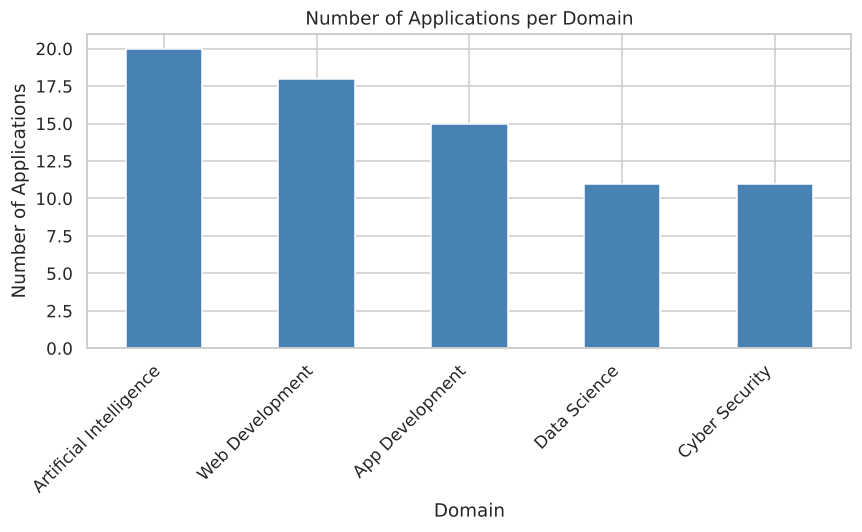

In [5]:
plt.figure(figsize=(8,5))
domain_counts.plot(kind='bar', color='steelblue')
plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Takeaway:** Artificial Intelligence received the most applications (20), almost double the least popular domains, Cyber Security and Data Science (11 each). AI and Web Development (18) together make up just over half of all applications.

## Question 2 — How did applications trend over time?

Each date is rounded down to its month with `.dt.to_period('M')`, then `groupby().size()` counts the rows (applications) in every month.

In [6]:
# Group by month
df['Application Month'] = df['Application Date'].dt.to_period('M')
monthly_trend = df.groupby('Application Month').size()
print(monthly_trend)

Application Month
2026-01     3
2026-02     6
2026-03     6
2026-04    13
2026-05     5
2026-06     7
2026-07     7
2026-08     3
2026-09     7
2026-10     4
2026-11    10
2026-12     4
Freq: M, dtype: int64


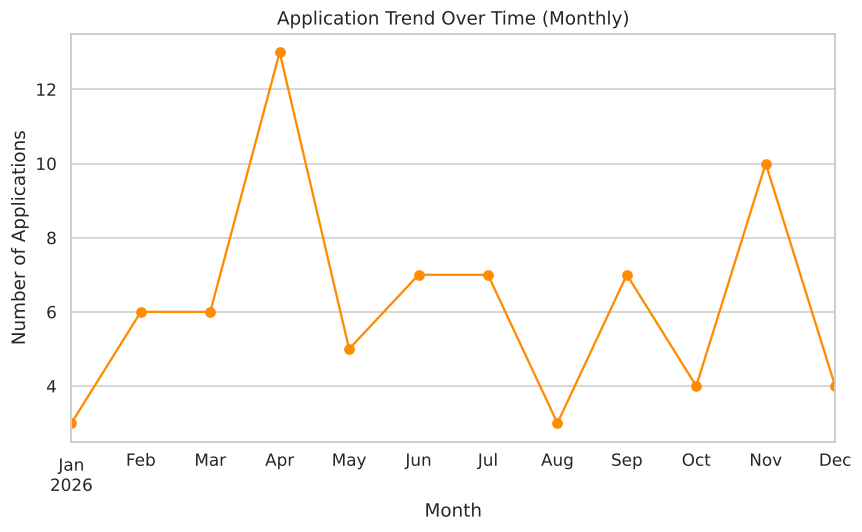

In [7]:
plt.figure(figsize=(8,5))
monthly_trend.plot(kind='line', marker='o', color='darkorange')
plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.tight_layout()
plt.show()

**Takeaway:** Applications peaked in April 2026 (13, about 17% of the total), then stayed in a 3 to 7 per month range until a second, smaller jump in November (10). January and August were the quietest months (3 each).

## Question 3 — What is the acceptance rate, overall and per domain?

First the overall status breakdown, then a `pivot_table()` of domain × status, then percentages so that domains with different numbers of applicants can be compared fairly.

In [8]:
status_counts = df['Status'].value_counts()
print(status_counts)

Status
Under Review    30
Selected        27
Rejected        18
Name: count, dtype: int64


In [9]:
status_by_domain = pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)
print(status_by_domain)

Status                   Rejected  Selected  Under Review
Domain Applied                                           
App Development                 2         6             7
Artificial Intelligence         4         6            10
Cyber Security                  2         5             4
Data Science                    2         5             4
Web Development                 8         5             5


In [10]:
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100
print(status_by_domain_pct.round(1))

Status                   Rejected  Selected  Under Review
Domain Applied                                           
App Development              13.3      40.0          46.7
Artificial Intelligence      20.0      30.0          50.0
Cyber Security               18.2      45.5          36.4
Data Science                 18.2      45.5          36.4
Web Development              44.4      27.8          27.8


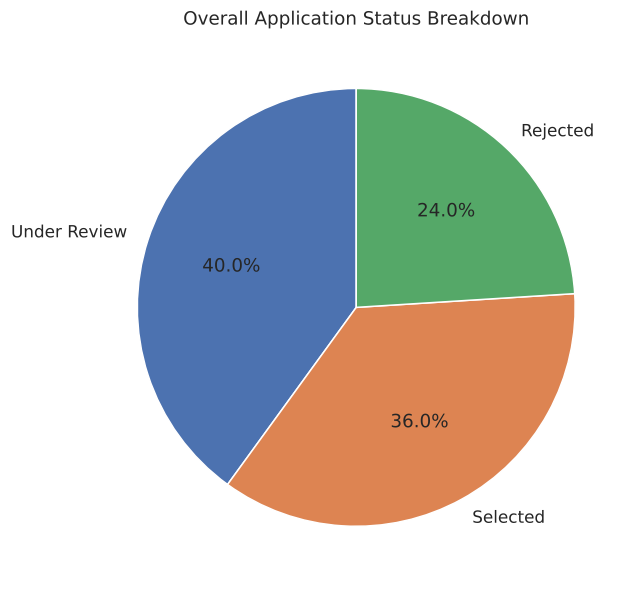

In [11]:
# Overall status - pie chart
plt.figure(figsize=(6,6))
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Overall Application Status Breakdown')
plt.ylabel('')  # removes the default awkward y-label pie charts add
plt.tight_layout()
plt.show()

**Takeaway (overall):** 36% of applicants (27) were Selected, 24% (18) were Rejected, and 40% (30) are still Under Review, so these rates can still change.

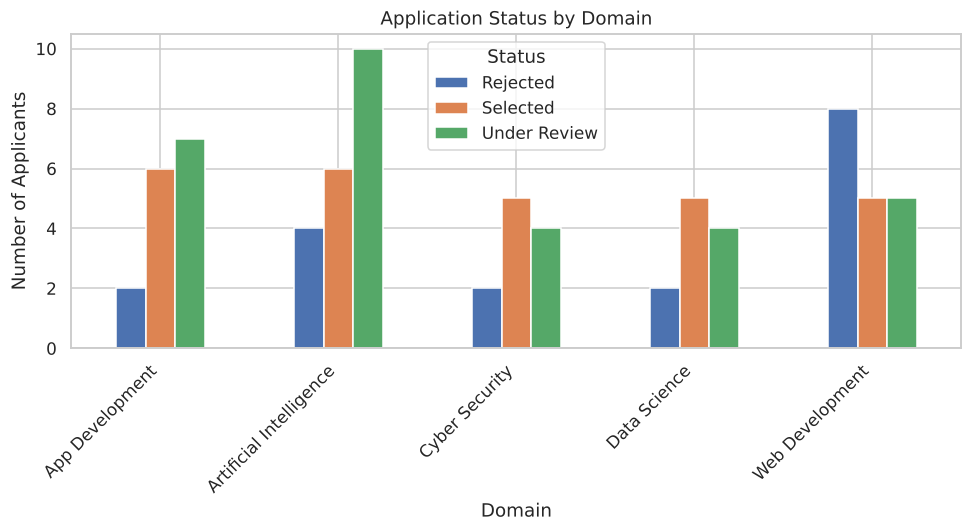

In [12]:
# Per-domain - grouped bar chart
status_by_domain.plot(kind='bar', figsize=(9,5))
plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')
plt.tight_layout()
plt.show()

**Takeaway (per domain):** Cyber Security and Data Science have the highest selection rate (45.5% each), followed by App Development (40.0%), Artificial Intelligence (30.0%) and Web Development (27.8%). Web Development also rejects the most: 8 of its 18 applicants (44.4%), against 13% to 20% in the other domains.

## Question 4 — Which universities sent the most applicants?

`.head(10)` keeps the top 10 only. This dataset has just 6 distinct university values, so all of them appear.

In [13]:
top_universities = df['University'].value_counts().head(10)
print(top_universities)

University
University Of Karachi    18
Ned University           17
Muet                     14
University Of Sindh      12
Szabist                  10
Not Specified             4
Name: count, dtype: int64


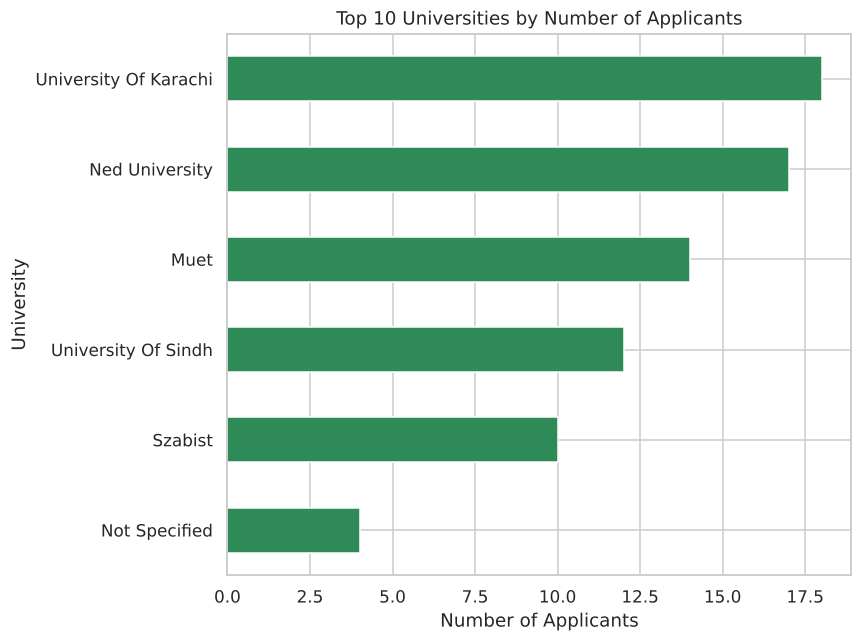

In [14]:
plt.figure(figsize=(8,6))
top_universities.sort_values().plot(kind='barh', color='seagreen')
plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')
plt.tight_layout()
plt.show()

**Takeaway:** University Of Karachi (18), Ned University (17) and Muet (14) together sent 49 of the 75 applicants (65%). 4 applicants did not state a university at all ("Not Specified").

## Bonus Question — On which day of the week do people apply?

**Why this question:** knowing the busiest days tells the team when to post reminders and when applicants are most likely to be online.

In [15]:
df['Day of Week'] = df['Application Date'].dt.day_name()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_counts = df['Day of Week'].value_counts().reindex(day_order)
print(weekday_counts)

Day of Week
Monday        9
Tuesday      14
Wednesday     6
Thursday     12
Friday        6
Saturday     10
Sunday       18
Name: count, dtype: int64


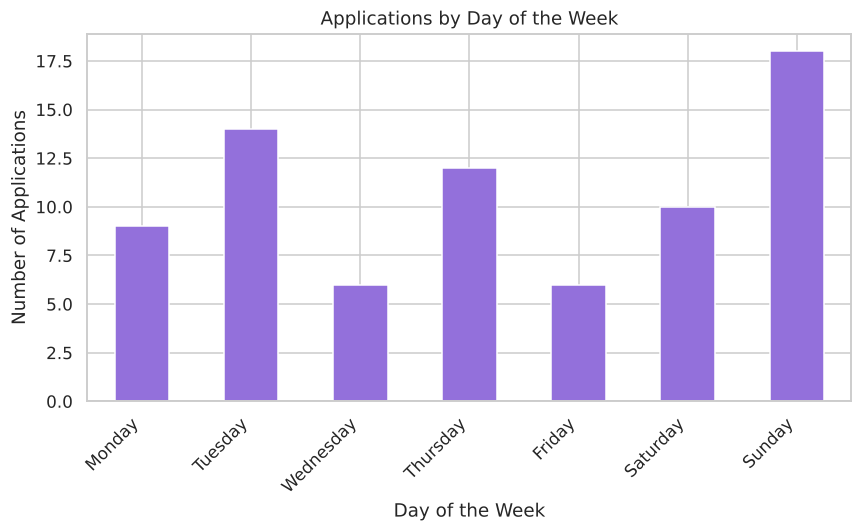

In [16]:
plt.figure(figsize=(8,5))
weekday_counts.plot(kind='bar', color='mediumpurple')
plt.title('Applications by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Takeaway:** Sunday is the busiest day by far (18 applications, 24%), followed by Tuesday (14). Saturday and Sunday together bring in 28 of 75 applications (37%), even though they are only 2 of 7 days.

## Key Insights

- **AI and Web Development attract the crowd.** Artificial Intelligence received the most applications (20 of 75, 27%), almost double Cyber Security and Data Science (11 each). AI and Web Development together account for half of all applications, so mentors and seats should be planned mainly around these two.
- **Smaller domains are easier to get into, and Web Development is the hardest.** Cyber Security and Data Science select 45.5% of their applicants, versus only 27.8% for Web Development, which also rejects 44.4% of its applicants. Promoting the two smaller domains could fill seats with less competition, and the team should check whether Web Development screening is too strict or applicants need better preparation material. (Each small domain has only 11 applicants, and 40% of all applicants are still Under Review, so these rates may shift.)
- **April was the best month for recruitment.** 13 applications (17% of the total) arrived in April 2026, more than any other month, with a smaller second peak of 10 in November. Repeating whatever outreach ran in April, and starting it earlier, is the most promising way to get more applicants.
- **Three universities supply two thirds of applicants.** University Of Karachi, Ned University and Muet sent 49 of 75 applicants (65%). Outreach events at these three campuses are the most efficient use of effort, while Szabist (10) and University Of Sindh (12) have room to grow. Also, 4 applicants left the university blank, so making that form field mandatory would improve future data.
- **Weekends are prime time.** Sunday alone brings in 24% of applications and the weekend as a whole 37%. Announcements and deadline reminders should go out on Friday evening or Saturday so they reach people when they are most active.